# p10_continuous_learning — incremental updates, refresh rules and the pilot KPIs

The platform is only useful if new notices, awards, supervision documents and amendments reach the graph, the models and the retrieval index without a full rebuild every day, and if someone can tell when a model has gone stale. This notebook shows the loop on real tables:

%md-sandbox
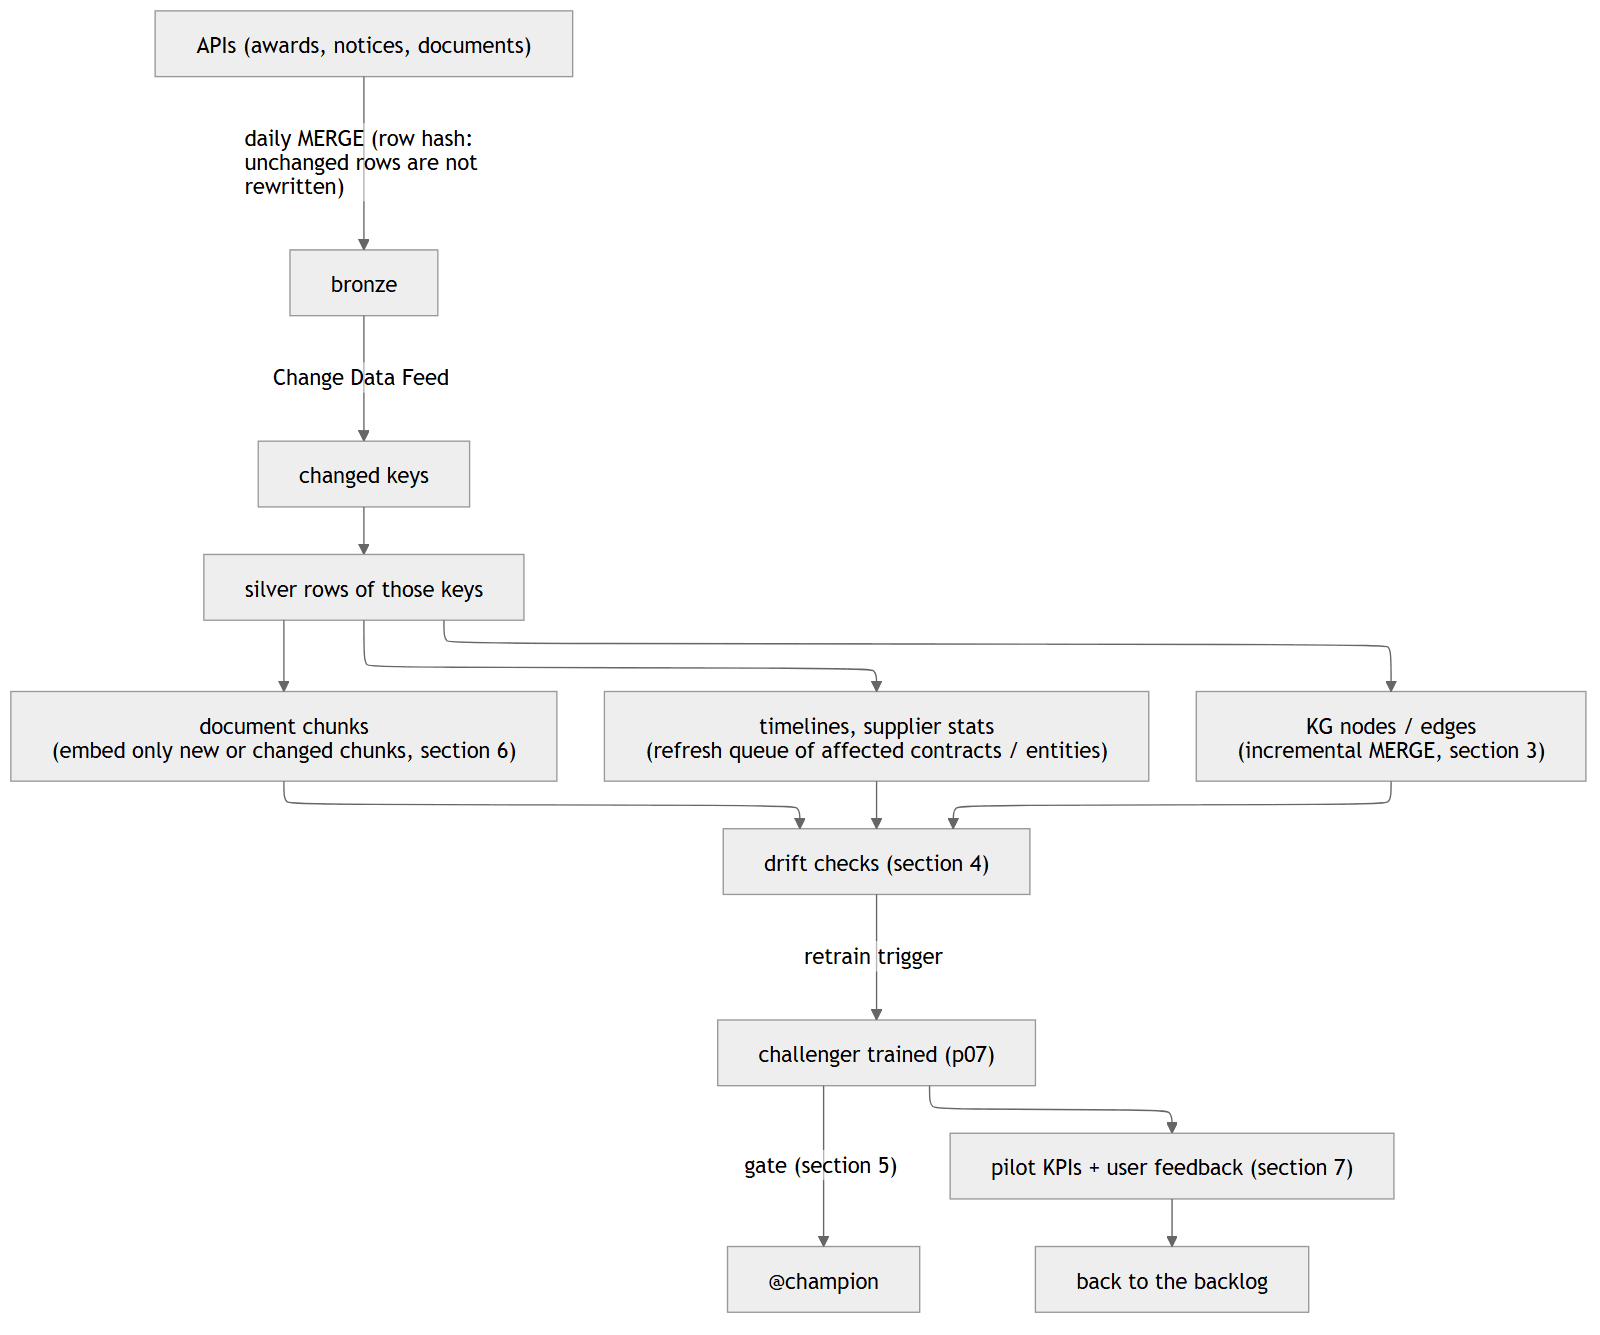

<details><summary>Diagram source (Mermaid)</summary>

<pre><code>---
config:
  layout: elk
  htmlLabels: false
  flowchart:
    htmlLabels: false
    wrappingWidth: 600
---
flowchart TD
    apis["APIs (awards, notices, documents)"]
    bronze["bronze"]
    keys["changed keys"]
    silver["silver rows of those keys"]
    kg["KG nodes / edges&lt;br/&gt;(incremental MERGE, section 3)"]
    stats["timelines, supplier stats&lt;br/&gt;(refresh queue of affected contracts / entities)"]
    chunks["document chunks&lt;br/&gt;(embed only new or changed chunks, section 6)"]
    drift["drift checks (section 4)"]
    chall["challenger trained (p07)"]
    champ["@champion"]
    kpis["pilot KPIs + user feedback (section 7)"]
    backlog["back to the backlog"]
    apis --&gt;|"daily MERGE (row hash: unchanged rows are not rewritten)"| bronze
    bronze --&gt;|"Change Data Feed"| keys --&gt; silver
    silver --&gt; kg
    silver --&gt; stats
    silver --&gt; chunks
    kg --&gt; drift
    stats --&gt; drift
    chunks --&gt; drift
    drift --&gt;|"retrain trigger"| chall
    chall --&gt;|"gate (section 5)"| champ
    chall --&gt; kpis --&gt; backlog
</code></pre>

</details>

| Output | Grain | Key |
|---|---|---|
| Change Data Feed on the proc bronze, silver and gold tables | table property | - |
| `proc_gold.pipeline_checkpoints` | last bronze version processed per table | `table_name` |
| `proc_sandbox.notices_replay`, `kg_notice_nodes_replay`, `kg_notice_edges_replay` | replay copies for the incremental proof | as in silver / gold |
| `proc_gold.drift_reports` | one drift measure per run and feature | `run_id, feature` |
| `proc_gold.pilot_kpis` | one KPI with definition, baseline, target and latest value | `kpi_id` |
| `proc_gold.pilot_feedback` | one user rating of one agent answer (empty until the pilot) | `feedback_id` |

The notebook has two modes (widget `mode`): `demo` runs everything, including the replay proof and the policy demos; `monitor` (the daily job in `databricks.yml`) runs only the checks that belong in production: Change Data Feed status, bronze changes since the last checkpoint, drift report, freshness and KPI refresh.

## Key design decisions

| Decision | Rationale | Evidence |
|---|---|---|
| Change Data Feed enabled on all `proc_bronze`, `proc_silver` and `proc_gold` tables; read on bronze; downstream updates made incremental with `MERGE` on the affected keys | Bronze is loaded with `MERGE` and a row hash, so its feed holds only real changes; overwritten silver and gold tables would list every row as deleted and re-inserted | No table had `delta.enableChangeDataFeed` set; the property changes no data; silver steps that still overwrite are the next candidates |
| Only the neighbourhood of changed notices is recomputed in the knowledge graph | A daily batch is small relative to the stored data | A day brings a few hundred notices against about 417,000 stored (silver notices per notice date in October 2026: 21 to 226) |
| Incremental path validated by replay in a separate `proc_sandbox` schema and compared with a full rebuild and with the production graph from `p06` | Writing a test batch into production would change what other components read mid-run | Replay: silver notices without the last 7 days and with 100 older notices in a "draft" version (half without a project id, half under a wrong project); today's batch = the held-back notices plus the corrected versions |
| Drift windows by signing date: the latest 12 months vs the 24 months before | Cohorts by notice date make recent durations look short (censoring) | A tender advertised last month appears only if it was already signed |
| Incremental path kept for change-feed correctness and scale; link, bidder and edge tables to be liquid-clustered by `notice_id` / `src_id` before relying on it for speed | At this size the incremental path is not faster, but it writes far less | Incremental 65-70 s vs full rebuild of the 1.36 million-edge neighbourhood 30-76 s over two runs; 3,290 inserts and 50 deletes instead of rewriting 1.36 million rows (3,340 changes in the feed) |
| Freshness = the newest data commit (write, merge, update, delete, create-as-select) | Metadata commits make every table look fresh | Using the newest commit reported every table as 0.5 hours old, because of this notebook's own `SET TBLPROPERTIES` |

Limitations: the incremental path still scans the whole link and bidder tables to find the changed rows, and the `MERGE` reads the whole target.

Full reasoning: docs/decision_log.md

In [ ]:
%run ./proc_common

## Settings

**What:** the mode, the tables that get a change feed, the replay sizes and the drift windows.

**Why:** one place to see what the notebook may alter: only tables in `proc_*` schemas, and only their properties, except for the sandbox copies and the monitoring tables it owns.

In [ ]:
import json
import time
from datetime import datetime, timedelta, timezone

from delta.tables import DeltaTable
from pyspark.sql import Window

from proc_intel.freshness import (champion_challenger_gate, drift_level, freshness_status, index_refresh_plan,
                                  ks_statistic, psi_categorical, psi_numeric, retrain_decision)
from proc_intel.http import get_json
from proc_intel.ingest import parse_wb_date

dbutils.widgets.dropdown("mode", "demo", ["demo", "monitor"])
MODE = dbutils.widgets.get("mode")
RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
SANDBOX = f"{CATALOG}.proc_sandbox"
CDF_TABLES = [f"{BRONZE}.contract_awards", f"{BRONZE}.procurement_notices",
              f"{SILVER}.contracts", f"{SILVER}.notices", f"{SILVER}.notice_contract_links", f"{SILVER}.notice_bidders",
              f"{GOLD}.tender_timelines", f"{GOLD}.kg_nodes", f"{GOLD}.kg_edges"]
BRONZE_TABLES = [f"{BRONZE}.contract_awards", f"{BRONZE}.procurement_notices"]
CHECKPOINTS = f"{GOLD}.pipeline_checkpoints"
DRIFT_TABLE = f"{GOLD}.drift_reports"
KPI_TABLE, FEEDBACK_TABLE = f"{GOLD}.pilot_kpis", f"{GOLD}.pilot_feedback"
HOLD_DAYS, N_CORRECTIONS = 7, 100
print(f"mode={MODE} run_id={RUN_ID}")

mode=demo run_id=20261020T233515Z


## 1. Change Data Feed: check, then enable

**What:** reads `delta.enableChangeDataFeed` of each table, sets it where it is missing, and shows the before/after state with each table's current version.

**Why:** the feed records, from the version where it is switched on, every inserted, updated (pre- and post-image) and deleted row with its commit version. It is the cheapest correct answer to "which keys changed since the last run". Setting it is idempotent; it never rewrites data.

In [ ]:
def table_version(table: str) -> int:
    return DeltaTable.forName(spark, table).history(1).select("version").first()[0]


def cdf_enabled(table: str) -> bool:
    props = {r.key: r.value for r in spark.sql(f"SHOW TBLPROPERTIES {table}").collect()}
    return props.get("delta.enableChangeDataFeed", "false").lower() == "true"


def cdf_enabled_since(table: str):
    """(version, timestamp) of the commit that switched the feed on, from the table history."""
    hist = (DeltaTable.forName(spark, table).history().filter("operation = 'SET TBLPROPERTIES'")
            .filter(F.col("operationParameters")["properties"].contains("enableChangeDataFeed"))
            .orderBy(F.desc("version")).select("version", "timestamp").first())
    return (hist.version, str(hist.timestamp)[:19]) if hist else (None, None)


cdf_rows = []
for t in CDF_TABLES:
    before = cdf_enabled(t)
    if not before:
        spark.sql(f"ALTER TABLE {t} SET TBLPROPERTIES (delta.enableChangeDataFeed = true)")
    since_v, since_ts = cdf_enabled_since(t)
    cdf_rows.append({"table": t, "cdf_before_this_run": before, "cdf_now": cdf_enabled(t), "version_now": table_version(t),
                     "feed_on_since_version": since_v, "feed_on_since": since_ts})
display(pd.DataFrame(cdf_rows))

table                                            | cdf_before_this_run | cdf_now | version_now | feed_on_since_version | feed_on_since      
-------------------------------------------------+---------------------+---------+-------------+-----------------------+--------------------
dbw_wb_outcome.proc_bronze.contract_awards       | True                | True    | 7           | 7                     | 2026-10-20 23:01:08
dbw_wb_outcome.proc_bronze.procurement_notices   | True                | True    | 8           | 8                     | 2026-10-20 23:01:20
dbw_wb_outcome.proc_silver.contracts             | True                | True    | 88          | 88                    | 2026-10-20 23:01:39
dbw_wb_outcome.proc_silver.notices               | True                | True    | 102         | 102                   | 2026-10-20 23:01:49
dbw_wb_outcome.proc_silver.notice_contract_links | True                | True    | 37          | 37                    | 2026-10-20 23:01:55
dbw_wb_outcom

## 2. Bronze changes since the last checkpoint, and the size of a real day

**What:**
1. For each bronze table, reads `table_changes()` from the version after the stored checkpoint to now, counts inserts, updates and deletes, counts the projects they touch, and moves the checkpoint forward. On the first run there is no checkpoint yet: the current version becomes the baseline.
2. Asks the notices API for the newest notices (newest first, until a page is older than 3 days) and the awards API for its row count, and compares both with bronze.

**Why:** (1) is the production hand-off: the daily job ingests with `MERGE`, then this step turns the change feed into a list of affected keys for the downstream refresh. (2) measures a real daily increment, which is what justifies incremental processing.

In [ ]:
if not spark.catalog.tableExists(CHECKPOINTS):
    spark.sql(f"""CREATE TABLE {CHECKPOINTS} (table_name STRING NOT NULL COMMENT 'PK. Bronze table',
                  last_version BIGINT COMMENT 'Last table version whose changes were processed',
                  processed_at TIMESTAMP COMMENT 'When') COMMENT 'Change Data Feed checkpoints of the daily pipeline (p10). Grain: one row per source table.'""")
    spark.sql(f"ALTER TABLE {CHECKPOINTS} ADD CONSTRAINT pk_pipeline_checkpoints PRIMARY KEY (table_name)")
saved = {r.table_name: r.last_version for r in spark.table(CHECKPOINTS).collect()}
change_rows = []
for table in BRONZE_TABLES:
    now_v = table_version(table)
    start = saved.get(table)
    if start is None:
        change_rows.append({"table": table, "from_version": None, "to_version": now_v, "note": "baseline set (first run)"})
    elif now_v > start:
        ch = spark.sql(f"SELECT * FROM table_changes('{table}', {start + 1}, {now_v})")
        counts = {r._change_type: r["count"] for r in ch.groupBy("_change_type").count().collect()}
        projects = ch.filter("_change_type <> 'update_preimage'").select("project_id").distinct().count()
        change_rows.append({"table": table, "from_version": start + 1, "to_version": now_v, **counts,
                            "projects_touched": projects, "note": "changes read"})
    else:
        change_rows.append({"table": table, "from_version": start, "to_version": now_v, "note": "no new commits"})
    spark.createDataFrame([(table, now_v)], "table_name string, last_version long").createOrReplaceTempView("_cp")
    spark.sql(f"""MERGE INTO {CHECKPOINTS} t USING _cp s ON t.table_name = s.table_name
                  WHEN MATCHED THEN UPDATE SET last_version = s.last_version, processed_at = current_timestamp()
                  WHEN NOT MATCHED THEN INSERT (table_name, last_version, processed_at)
                  VALUES (s.table_name, s.last_version, current_timestamp())""")
display(pd.DataFrame(change_rows))

table                                          | from_version | to_version | note          
-----------------------------------------------+--------------+------------+---------------
dbw_wb_outcome.proc_bronze.contract_awards     | 7            | 7          | no new commits
dbw_wb_outcome.proc_bronze.procurement_notices | 8            | 8          | no new commits

In [ ]:
today = datetime.now(timezone.utc).date()
recent, pages = [], 0
while pages < 20:
    body = get_json(NOTICES_URL, {"format": "json", "srt": "id", "order": "desc", "rows": 500, "os": pages * 500,
                                  "fl": "id,noticedate,notice_type"})
    batch = [v for v in body.get("procnotices", [])]
    recent.extend(batch)
    pages += 1
    dates = [d for d in (parse_wb_date(v.get("noticedate")) for v in batch) if d]
    if not batch or (dates and max(dates) < today - timedelta(days=3)):
        break
api = spark.createDataFrame([(v["id"], v.get("noticedate"), v.get("notice_type")) for v in recent],
                            "id string, noticedate string, notice_type string")
known = api.join(spark.table(f"{BRONZE}.procurement_notices").select("id"), "id", "left_semi").count()
awards_body = get_json(AWARDS_URL, {**AWARDS_PARAMS, "top": 1})
awards_api = int(awards_body.get("count", 0))
awards_bronze = spark.table(f"{BRONZE}.contract_awards").filter("_removed_at_source IS NULL").count()
print(f"notices API, newest {len(recent):,} notices ({pages} pages): {len(recent) - known:,} not yet in bronze, {known:,} already loaded")
print(f"awards API row count {awards_api:,} vs bronze active rows {awards_bronze:,} (difference {awards_api - awards_bronze:+,})")

notices API, newest 2,000 notices (4 pages): 0 not yet in bronze, 2,000 already loaded
awards API row count 295,058 vs bronze active rows 295,058 (difference +0)


## 3. Incremental update of the knowledge graph, proven against a full rebuild

**What:** the notice neighbourhood of the graph (notice nodes; `FOR_PROJECT`, `ADVERTISES`, `ANNOUNCES`, `BID_ON` edges) built by the same rules as `p06`, in the sandbox:

| Step | Content |
|---|---|
| yesterday | silver notices without the last 7 days of notice dates; 100 older notices (hash order) in a "draft" version: description prefixed `[draft]`; 50 without a project id, 50 filed under a wrong project |
| today's batch | the held-back notices and the corrected versions of the 100 |
| ingest | `MERGE` on `notice_id` with a row hash into `notices_replay` (change feed on) |
| changed keys | `table_changes()` since the version before the merge |
| incremental | recompute nodes and edges of the changed notices only; one atomic `MERGE` that inserts, updates and deletes (edges that no longer exist arrive as tombstones) |
| proof | incremental result = full rebuild (whole table and changed keys) and = the production `kg_nodes` / `kg_edges` |

**Why:** the comparison with a full rebuild is the correctness test of the incremental path; the comparison with production shows the sandbox builder is the same as `p06`'s. Links and bidder rows of a notice come from the silver tables built by `p03` / `p05` (in production those steps produce them for the new notices before this one runs).

In [ ]:
def props(*cols: str):
    """String map of the given columns, dropping nulls (as in p06)."""
    pairs = [x for c in cols for x in (F.lit(c), F.col(c).cast("string"))]
    return F.map_filter(F.create_map(*pairs), lambda k, v: v.isNotNull())


def canonical(df: DataFrame) -> DataFrame:
    """Adds properties_json: the property map as sorted JSON, comparable in EXCEPT and MERGE conditions."""
    return df.withColumn("properties_json", F.to_json(F.array_sort(F.map_entries("properties"))))


def notice_subgraph(notices: DataFrame) -> tuple[DataFrame, DataFrame]:
    """Notice nodes and the edges that touch a notice, by p06's rules, for the given notices only."""
    ids = notices.select("notice_id")
    links = spark.table(f"{SILVER}.notice_contract_links").join(ids, "notice_id", "left_semi")
    bid_on = (spark.table(f"{SILVER}.notice_bidders").join(ids, "notice_id", "left_semi")
              .join(spark.table(f"{SILVER}.supplier_entity_map"), "supplier_id")
              .withColumn("_rank", F.when(F.col("role") == "awarded", 0).when(F.col("role") == "evaluated", 1).otherwise(2))
              .withColumn("_rn", F.row_number().over(Window.partitionBy("supplier_entity_id", "notice_id").orderBy("_rank")))
              .filter("_rn = 1"))
    nodes = notices.select(F.concat(F.lit("notice:"), "notice_id").alias("node_id"), F.lit("notice").alias("node_type"),
                           F.col("bid_description").alias("name"),
                           props("notice_type", "notice_date", "procurement_method_name", "procurement_category_code",
                                 "bid_reference", "submission_deadline").alias("properties"))

    def edge(df, src, src_key, etype, dst, dst_key, *cols):
        return (df.filter(F.col(src_key).isNotNull() & F.col(dst_key).isNotNull())
                .select(F.concat(F.lit(f"{src}:"), F.col(src_key)).alias("src_id"), F.lit(etype).alias("edge_type"),
                        F.concat(F.lit(f"{dst}:"), F.col(dst_key)).alias("dst_id"), props(*cols).alias("properties")))

    edges = (edge(notices, "notice", "notice_id", "FOR_PROJECT", "project", "project_id")
             .unionByName(edge(links.filter("link_role = 'tender'"), "notice", "notice_id", "ADVERTISES", "contract",
                               "contract_id", "match_tier", "notice_before_signing", "days_notice_to_signing"))
             .unionByName(edge(links.filter("link_role = 'award'"), "notice", "notice_id", "ANNOUNCES", "contract",
                               "contract_id", "match_tier", "supplier_confirmed"))
             .unionByName(edge(bid_on, "supplier_entity", "supplier_entity_id", "BID_ON", "notice", "notice_id", "role")))
    return canonical(nodes), canonical(edges)


NOTICE_EDGE_TYPES = ["FOR_PROJECT", "ADVERTISES", "ANNOUNCES", "BID_ON"]
EDGE_KEY, NODE_KEY = ["src_id", "edge_type", "dst_id"], ["node_id"]


def diff_count(a: DataFrame, b: DataFrame, cols: list[str]) -> int:
    """Rows in a but not b plus rows in b but not a (on the given columns)."""
    a, b = a.select(*cols), b.select(*cols)
    return a.exceptAll(b).count() + b.exceptAll(a).count()

**What:** yesterday's state in the sandbox: the replay notices table (change feed on) and the graph neighbourhood built from it.

**Why:** a self-contained starting point whose "true" final state is known: after today's batch it must equal the current silver notices exactly.

In [ ]:
if MODE == "demo":
    spark.sql(f"CREATE SCHEMA IF NOT EXISTS {SANDBOX} COMMENT 'Replay copies for testing incremental updates (p10). Not read by any other step.'")
    REPLAY_NOTICES = f"{SANDBOX}.notices_replay"
    REPLAY_NODES, REPLAY_EDGES = f"{SANDBOX}.kg_notice_nodes_replay", f"{SANDBOX}.kg_notice_edges_replay"
    silver_notices = spark.table(f"{SILVER}.notices")
    business_cols = silver_notices.columns
    hold_from = silver_notices.agg(F.max("notice_date")).first()[0] - timedelta(days=HOLD_DAYS - 1)
    corrected_ids = (silver_notices.filter((F.col("notice_date") < F.lit(hold_from)) & F.col("project_id").isNotNull())
                     .orderBy(F.sha2("notice_id", 256)).limit(N_CORRECTIONS).select("notice_id")
                     .withColumn("_corr", F.lit(True))
                     .withColumn("_corr_n", F.row_number().over(Window.orderBy(F.sha2("notice_id", 256)))))
    wrong_project = spark.table(f"{SILVER}.dim_project").agg(F.min("project_id")).first()[0]     # any real project
    yesterday = (silver_notices.filter((F.col("notice_date") < F.lit(hold_from)) | F.col("notice_date").isNull())
                 .join(corrected_ids, "notice_id", "left")
                 .withColumn("project_id", F.when(F.col("_corr") & (F.col("_corr_n") % 2 == 0), F.lit(None).cast("string"))
                             .when(F.col("_corr"), F.lit(wrong_project)).otherwise(F.col("project_id")))
                 .withColumn("bid_description", F.when(F.col("_corr"), F.concat(F.lit("[draft] "), "bid_description"))
                             .otherwise(F.col("bid_description")))
                 .select(*business_cols).withColumn("_row_hash", row_hash(business_cols)))
    spark.sql(f"DROP TABLE IF EXISTS {REPLAY_NOTICES}")
    yesterday.write.saveAsTable(REPLAY_NOTICES)
    spark.sql(f"ALTER TABLE {REPLAY_NOTICES} SET TBLPROPERTIES (delta.enableChangeDataFeed = true)")
    y_nodes, y_edges = notice_subgraph(spark.table(REPLAY_NOTICES))
    y_nodes.write.mode("overwrite").option("overwriteSchema", "true").saveAsTable(REPLAY_NODES)
    y_edges.write.mode("overwrite").option("overwriteSchema", "true").saveAsTable(REPLAY_EDGES)
    for t, text in [(REPLAY_NOTICES, "Replay of proc_silver.notices: yesterday = without the last 7 days, 100 notices in draft form; then today's batch merged (p10)."),
                    (REPLAY_NODES, "Replay: notice nodes of the knowledge graph, maintained incrementally (p10)."),
                    (REPLAY_EDGES, "Replay: edges touching a notice (FOR_PROJECT, ADVERTISES, ANNOUNCES, BID_ON), maintained incrementally (p10).")]:
        spark.sql(f"COMMENT ON TABLE {t} IS '{_quote(text)}'")
    v_before = table_version(REPLAY_NOTICES)
    print(f"held back notices dated >= {hold_from}; yesterday: {spark.table(REPLAY_NOTICES).count():,} notices, "
          f"{spark.table(REPLAY_NODES).count():,} nodes, {spark.table(REPLAY_EDGES).count():,} edges; "
          f"replay table at version {v_before}, change feed {cdf_enabled(REPLAY_NOTICES)}")

held back notices dated >= 2026-10-13; yesterday: 378,886 notices, 378,886 nodes, 1,361,013 edges; replay table at version 2, change feed True


**What:** today's batch merged into the replay notices, then the change feed since the version before the merge, and what it means downstream: which projects, contracts (and so `tender_timelines` rows) and supplier entities are touched.

**Why:** this is the refresh queue a production run would hand to the timeline, supplier-statistics and graph steps. It also shows why the change feed beats a full comparison: the 100 corrected notices are found without comparing 380,000 rows.

In [ ]:
if MODE == "demo":
    batch = (silver_notices.filter(F.col("notice_date") >= F.lit(hold_from))
             .unionByName(silver_notices.join(corrected_ids.select("notice_id"), "notice_id", "left_semi"))
             .withColumn("_row_hash", row_hash(business_cols)))
    merge_metrics = merge_upsert(batch, REPLAY_NOTICES, "notice_id")
    print("MERGE of today's batch:", merge_metrics)
    changes = spark.sql(f"SELECT * FROM table_changes('{REPLAY_NOTICES}', {v_before + 1})")
    display(changes.groupBy("_change_type").count())
    changed = changes.filter("_change_type <> 'update_preimage'").select("notice_id").distinct().cache()
    changed_nodes = changed.select(F.concat(F.lit("notice:"), "notice_id").alias("node_id"))
    new_nodes, new_edges = notice_subgraph(spark.table(REPLAY_NOTICES).join(changed, "notice_id", "left_semi"))
    old_edges = spark.table(REPLAY_EDGES)
    touching_old = (old_edges.join(changed_nodes.withColumnRenamed("node_id", "src_id"), "src_id", "left_semi")
                    .unionByName(old_edges.join(changed_nodes.withColumnRenamed("node_id", "dst_id"), "dst_id", "left_semi")))
    touched = new_edges.unionByName(touching_old)
    impact = {"changed notices": changed.count(),
              "projects (FOR_PROJECT, old or new)": touched.filter("edge_type = 'FOR_PROJECT'").select("dst_id").distinct().count(),
              "contracts (ADVERTISES / ANNOUNCES)": touched.filter("edge_type IN ('ADVERTISES', 'ANNOUNCES')").select("dst_id").distinct().count(),
              "tender_timelines rows to refresh": spark.table(f"{GOLD}.tender_timelines")
                  .join(touched.filter("edge_type IN ('ADVERTISES', 'ANNOUNCES')")
                        .select(F.regexp_replace("dst_id", "^contract:", "").alias("contract_id")).distinct(), "contract_id", "left_semi").count(),
              "supplier entities (BID_ON)": touched.filter("edge_type = 'BID_ON'").select("src_id").distinct().count()}
    display(pd.DataFrame([impact]))

MERGE of today's batch: {'numSourceRows': 1034, 'numTargetRowsInserted': 934, 'numTargetRowsUpdated': 100, 'numTargetRowsNotMatchedBySourceUpdated': 0}


_change_type     | count
-----------------+------
update_preimage  | 100  
update_postimage | 100  
insert           | 934  

changed notices | projects (FOR_PROJECT, old or new) | contracts (ADVERTISES / ANNOUNCES) | tender_timelines rows to refresh | supplier entities (BID_ON)
----------------+------------------------------------+------------------------------------+----------------------------------+---------------------------
1034            | 432                                | 106                                | 106                              | 1932                      

**What:** the incremental update itself. The source of one `MERGE` per table is the recomputed rows of the changed notices plus *tombstones*: rows that touch a changed notice in the table but are no longer produced (here: the 50 `FOR_PROJECT` edges of draft notices filed under the wrong project; the 50 draft notices without a project get their edge inserted). Matched tombstones are deleted, changed rows updated, new rows inserted, all in one commit.

**Why:** a reader never sees a half-updated neighbourhood (delete-then-insert would expose an intermediate state), and unchanged rows are not rewritten.

In [ ]:
def incremental_merge(target: str, recomputed: DataFrame, touching: DataFrame, key: list[str]) -> dict:
    """MERGE recomputed rows into target; rows of `touching` that are not recomputed are deleted."""
    tomb = touching.join(recomputed.select(*key), key, "left_anti").withColumn("_delete", F.lit(True))
    source = recomputed.withColumn("_delete", F.lit(False)).unionByName(tomb)
    cond = " AND ".join(f"t.{k} = s.{k}" for k in key)
    cols = recomputed.columns
    changed_row = "t.properties_json <> s.properties_json" + (" OR NOT (t.name <=> s.name)" if "name" in cols else "")
    (DeltaTable.forName(spark, target).alias("t").merge(source.alias("s"), cond)
     .whenMatchedDelete(condition="s._delete")
     .whenMatchedUpdate(condition=f"NOT s._delete AND ({changed_row})", set={c: f"s.{c}" for c in cols})
     .whenNotMatchedInsert(condition="NOT s._delete", values={c: f"s.{c}" for c in cols})
     .execute())
    m = DeltaTable.forName(spark, target).history(1).select("operationMetrics").first()[0]
    return {k: int(m.get(k, 0)) for k in ["numTargetRowsInserted", "numTargetRowsUpdated", "numTargetRowsDeleted"]}


if MODE == "demo":
    t0 = time.time()
    old_nodes = spark.table(REPLAY_NODES).join(changed_nodes, "node_id", "left_semi")
    node_metrics = incremental_merge(REPLAY_NODES, new_nodes, old_nodes, NODE_KEY)
    edge_metrics = incremental_merge(REPLAY_EDGES, new_edges, touching_old, EDGE_KEY)   # no duplicates: an edge has a notice at one end only
    incremental_s = time.time() - t0
    t0 = time.time()
    full_nodes, full_edges = notice_subgraph(spark.table(REPLAY_NOTICES))
    full_edges.write.mode("overwrite").option("overwriteSchema", "true").saveAsTable(f"{SANDBOX}._kg_notice_edges_rebuild")
    full_s = time.time() - t0
    rewritten = spark.table(f"{SANDBOX}._kg_notice_edges_rebuild").count()
    print(f"incremental: nodes {node_metrics}, edges {edge_metrics} in {incremental_s:.0f} s")
    print(f"full rebuild of the edges: {rewritten:,} rows rewritten in {full_s:.0f} s")

incremental: nodes {'numTargetRowsInserted': 934, 'numTargetRowsUpdated': 100, 'numTargetRowsDeleted': 0}, edges {'numTargetRowsInserted': 3290, 'numTargetRowsUpdated': 0, 'numTargetRowsDeleted': 50} in 65 s
full rebuild of the edges: 1,364,253 rows rewritten in 30 s


**What:** the proof: differences (rows in one but not the other, both ways) between the incrementally maintained tables and (a) a full rebuild from today's replay notices, overall and on the changed keys, and (b) the production graph built by `p06` from the current silver tables.

**Why:** all must be 0. (b) also checks that the sandbox builder applies `p06`'s rules: after today's batch the replay notices equal silver, so the neighbourhood must equal production.

In [ ]:
if MODE == "demo":
    inc_nodes, inc_edges = spark.table(REPLAY_NODES), spark.table(REPLAY_EDGES)
    full_edges = spark.table(f"{SANDBOX}._kg_notice_edges_rebuild")
    prod_nodes = canonical(spark.table(f"{GOLD}.kg_nodes").filter("node_type = 'notice'"))
    prod_edges = canonical(spark.table(f"{GOLD}.kg_edges").filter(F.col("edge_type").isin(NOTICE_EDGE_TYPES)))
    node_cols, edge_cols = ["node_id", "node_type", "name", "properties_json"], EDGE_KEY + ["properties_json"]
    on_changed = lambda df, col: df.join(changed_nodes.withColumnRenamed("node_id", col), col, "left_semi")
    proof = [
        (REPLAY_NODES, "incremental vs full rebuild: all notice nodes", diff_count(inc_nodes, full_nodes, node_cols), "== 0"),
        (REPLAY_EDGES, "incremental vs full rebuild: all notice edges", diff_count(inc_edges, full_edges, edge_cols), "== 0"),
        (REPLAY_EDGES, "incremental vs full rebuild: edges of changed notices",
         diff_count(on_changed(inc_edges, "src_id").unionByName(on_changed(inc_edges, "dst_id")),
                    on_changed(full_edges, "src_id").unionByName(on_changed(full_edges, "dst_id")), edge_cols), "== 0"),
        (REPLAY_NODES, "incremental vs production kg_nodes (notice)", diff_count(inc_nodes, prod_nodes, node_cols), "== 0"),
        (REPLAY_EDGES, "incremental vs production kg_edges (notice edge types)", diff_count(inc_edges, prod_edges, edge_cols), "== 0"),
        (REPLAY_NOTICES, "replay notices vs silver notices", diff_count(spark.table(REPLAY_NOTICES), silver_notices, business_cols), "== 0"),
        (REPLAY_EDGES, "edges in the neighbourhood", inc_edges.count(), "info"),
    ]
    display(dq_report(proof))

table                                              | check                                                  | value   | rule | status
---------------------------------------------------+--------------------------------------------------------+---------+------+-------
dbw_wb_outcome.proc_sandbox.kg_notice_nodes_replay | incremental vs full rebuild: all notice nodes          | 0       | == 0 | pass  
dbw_wb_outcome.proc_sandbox.kg_notice_edges_replay | incremental vs full rebuild: all notice edges          | 0       | == 0 | pass  
dbw_wb_outcome.proc_sandbox.kg_notice_edges_replay | incremental vs full rebuild: edges of changed notices  | 0       | == 0 | pass  
dbw_wb_outcome.proc_sandbox.kg_notice_nodes_replay | incremental vs production kg_nodes (notice)            | 0       | == 0 | pass  
dbw_wb_outcome.proc_sandbox.kg_notice_edges_replay | incremental vs production kg_edges (notice edge types) | 0       | == 0 | pass  
dbw_wb_outcome.proc_sandbox.notices_replay         | replay no

## 4. Drift checks on the modelling population

**What:** openly competed, timed contracts of `tender_timelines` (the population of the delay model), in two windows by signing date: **current** = the latest 12 months, **reference** = the 24 months before. For each key feature the population stability index (PSI; numeric features binned at the reference deciles), and for the target (days from notice to signing) the Kolmogorov-Smirnov statistic and the medians. Appended to `proc_gold.drift_reports`.

**Why:** the model learns "how long does a tender like this take"; if the mix of contracts (size, category, method, region, governance) or the durations themselves move, the champion's errors on new tenders will move too. PSI bands: below 0.10 stable, 0.10-0.25 moderate, 0.25 or more significant.

In [ ]:
pop = (spark.table(f"{GOLD}.tender_timelines").filter("is_timed AND competition = 'open'")
       .select("signing_date", "contract_amount_usd", "procurement_category_code", "procurement_method_name", "region",
               "wgi_gov_effectiveness", "days_notice_to_signing"))
last_signing = pop.agg(F.max("signing_date")).first()[0]
cur_from, ref_from = last_signing - timedelta(days=365), last_signing - timedelta(days=3 * 365)
windowed = (pop.withColumn("window", F.when(F.col("signing_date") > F.lit(cur_from), "current")
                           .when(F.col("signing_date") > F.lit(ref_from), "reference"))
            .filter("window IS NOT NULL")
            .withColumn("log10_amount", F.log10(F.greatest(F.col("contract_amount_usd"), F.lit(1.0)))))
wp = windowed.drop("signing_date", "contract_amount_usd").toPandas()          # about 20k rows, 7 columns
ref, cur = wp[wp.window == "reference"], wp[wp.window == "current"]
drift = []
for feat in ["log10_amount", "wgi_gov_effectiveness"]:
    drift.append({"feature": feat, "kind": "numeric", "metric": "psi", "value": psi_numeric(ref[feat].tolist(), cur[feat].tolist())})
for feat in ["procurement_category_code", "procurement_method_name", "region"]:
    drift.append({"feature": feat, "kind": "categorical", "metric": "psi",
                  "value": psi_categorical(ref[feat].fillna("(none)").value_counts().to_dict(),
                                           cur[feat].fillna("(none)").value_counts().to_dict())})
target_ks = ks_statistic(ref["days_notice_to_signing"].tolist(), cur["days_notice_to_signing"].tolist())
drift.append({"feature": "days_notice_to_signing", "kind": "target", "metric": "ks", "value": target_ks})
drift.append({"feature": "days_notice_to_signing", "kind": "target", "metric": "psi",
              "value": psi_numeric(ref["days_notice_to_signing"].tolist(), cur["days_notice_to_signing"].tolist())})
for d in drift:
    d.update({"run_id": RUN_ID, "reference_window": f"{ref_from + timedelta(days=1)}..{cur_from}",
              "current_window": f"{cur_from + timedelta(days=1)}..{last_signing}", "n_reference": len(ref), "n_current": len(cur),
              "level": drift_level(d["value"]) if d["metric"] == "psi" else ("shift" if d["value"] >= 0.10 else "stable"),
              "value": round(float(d["value"]), 4)})
drift_df = spark.createDataFrame(pd.DataFrame(drift)[["run_id", "feature", "kind", "metric", "value", "level",
                                                     "reference_window", "current_window", "n_reference", "n_current"]])
drift_df = drift_df.withColumn("feature", F.concat_ws(":", "feature", "metric")).withColumn("measured_at", F.current_timestamp())
DRIFT_COMMENTS = {"run_id": "PK. Run timestamp (UTC)", "feature": "PK. <feature>:<metric>", "kind": "numeric, categorical or target",
                  "metric": "psi or ks", "value": "Measured value", "level": "stable / moderate / significant (PSI); stable / shift (KS >= 0.10)",
                  "reference_window": "Signing dates of the reference window", "current_window": "Signing dates of the current window",
                  "n_reference": "Contracts in the reference window", "n_current": "Contracts in the current window", "measured_at": "Timestamp"}
if spark.catalog.tableExists(DRIFT_TABLE):
    drift_df.write.mode("append").saveAsTable(DRIFT_TABLE)
else:
    publish_table(drift_df, DRIFT_TABLE, "Drift checks of the delay-model population (p10). Grain: one row per run and feature:metric. Appended daily.",
                  DRIFT_COMMENTS, primary_key=["run_id", "feature"])
display(drift_df.drop("run_id", "measured_at"))
print(f"median days notice->signing: reference {ref['days_notice_to_signing'].median():.0f}, current {cur['days_notice_to_signing'].median():.0f}")

feature                       | kind        | metric | value  | level  | reference_window       | current_window         | n_reference | n_current
------------------------------+-------------+--------+--------+--------+------------------------+------------------------+-------------+----------
log10_amount:psi              | numeric     | psi    | 0.0842 | stable | 2023-10-14..2025-10-12 | 2025-10-13..2026-10-12 | 10336       | 3901     
wgi_gov_effectiveness:psi     | numeric     | psi    | 0.085  | stable | 2023-10-14..2025-10-12 | 2025-10-13..2026-10-12 | 10336       | 3901     
procurement_category_code:psi | categorical | psi    | 0.0036 | stable | 2023-10-14..2025-10-12 | 2025-10-13..2026-10-12 | 10336       | 3901     
procurement_method_name:psi   | categorical | psi    | 0.0146 | stable | 2023-10-14..2025-10-12 | 2025-10-13..2026-10-12 | 10336       | 3901     
region:psi                    | categorical | psi    | 0.0234 | stable | 2023-10-14..2025-10-12 | 2025-10-13..2026-10-

median days notice->signing: reference 153, current 160


## 5. Retrain trigger and champion/challenger gate

**What:** `retrain_decision()` applied to the drift measured above, as if the champion had been trained on the reference window; then `champion_challenger_gate()` on two example metric sets (the gate takes metrics; the delay model itself and its evaluation belong to `p07`).

| Rule | Trigger / requirement |
|---|---|
| retrain | any key feature PSI >= 0.25, target KS >= 0.10, live MAE more than 15% above the training MAE, or the model is 90+ days old ... |
| ... but only with data | at least 1,000 new labelled contracts; otherwise "investigate" (retraining on a handful of outcomes is noise) |
| promote | same evaluation window (the latest one) for both; at least 500 rows; challenger MAE at least 2% lower; no segment (category, region) with 50+ rows more than 10% worse; prediction-interval coverage within 5 points of nominal |

**Why:** the trigger and the gate are separate on purpose. Drift says the world moved; only the gate decides whether a new model is better on the newest data. Promotion means moving the MLflow alias `@champion` to the challenger's version, so serving code never changes and a rollback is moving the alias back.

In [ ]:
feature_psi = {d["feature"]: d["value"] for d in drift if d["metric"] == "psi" and d["kind"] != "target"}
decision = retrain_decision(feature_psi, target_ks, days_since_training=(today - cur_from).days, new_labels=len(cur))
print(json.dumps(decision, indent=1))
if MODE == "demo":
    champion = {"window": "latest-12m", "n": 4000, "mae": 62.0, "segments": {"CS": {"n": 900, "mae": 95.0}, "CW": {"n": 1500, "mae": 58.0}}}
    examples = {"better overall and in every segment": {"window": "latest-12m", "n": 4000, "mae": 58.5,
                                                        "segments": {"CS": {"n": 900, "mae": 93.0}, "CW": {"n": 1500, "mae": 55.0}},
                                                        "interval_coverage": 0.78, "nominal_coverage": 0.8},
                "better overall, worse on consulting": {"window": "latest-12m", "n": 4000, "mae": 57.0,
                                                        "segments": {"CS": {"n": 900, "mae": 108.0}, "CW": {"n": 1500, "mae": 50.0}}}}
    gate_rows = []
    for name, ch in examples.items():
        g = champion_challenger_gate(champion, ch)
        gate_rows.append({"challenger (example metrics)": name, "promote": g["promote"], "reason": g["reason"],
                          "checks": "; ".join(f"{n}: {'pass' if ok else 'FAIL'} ({d})" for n, ok, d in g["checks"])})
    display(pd.DataFrame(gate_rows))

{
 "action": "retrain",
 "retrain": true,
 "reasons": [
  "model is 373 days old (scheduled refresh at 90)"
 ]
}


challenger (example metrics)        | promote | reason                           | checks                                                                                                                                                                                                                                                                                                       
------------------------------------+---------+----------------------------------+--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
better overall and in every segment | True    | all checks passed                | same evaluation window: pass (latest-12m vs latest-12m); enough evaluation rows: pass (n=4000 (min 500)); overall MAE improves: pass (58.50 vs cham

## 6. Retrieval index refresh

**What:** `index_refresh_plan()` compares chunk id -> text hash of what the index holds with the current chunk table and returns what to embed (new or changed chunks), what to delete (removed or changed) and how many stay. Shown on the outcome project's 50,000 chunks, with a simulated day: 3 documents re-chunked (text changed), 1 document withdrawn, and new chunks for the ISR and ICR Review texts collected in `p09` for 5 projects (counted as 1 chunk per document here).

**Why:** embedding is the expensive step of an index refresh; hashing the chunk text makes "has this chunk changed?" exact and cheap, so a daily refresh embeds a few dozen chunks instead of 50,000. The FAISS index is then patched (remove ids, add vectors) or rebuilt from the stored embeddings, which needs no new embedding calls.

In [ ]:
if MODE == "demo":
    chunk_rows = spark.table(RAG_CHUNKS).select("chunk_id", "doc_id", "text_hash").collect()     # 50k short rows
    indexed = {r.chunk_id: r.text_hash for r in chunk_rows}
    doc_of = {r.chunk_id: r.doc_id for r in chunk_rows}
    docs = sorted(set(doc_of.values()))[:4]                                    # first 4 documents by id
    rechunked, withdrawn = set(docs[:3]), docs[3]
    current = {cid: (h + "-v2" if doc_of[cid] in rechunked else h) for cid, h in indexed.items() if doc_of[cid] != withdrawn}
    if spark.catalog.tableExists(f"{BRONZE}.rating_documents"):
        first_projects = (spark.table(f"{BRONZE}.rating_documents").select("project_id").distinct()
                          .orderBy("project_id").limit(5))
        new_docs = (spark.table(f"{BRONZE}.rating_documents").filter("doc_id IS NOT NULL")
                    .join(first_projects, "project_id", "left_semi").select("doc_id").collect())
        current.update({f"{r.doc_id}_0": f"hash-{r.doc_id}" for r in new_docs})
    plan = index_refresh_plan(indexed, current)
    display(pd.DataFrame([{"chunks indexed": len(indexed), "chunks now": len(current), "to embed": len(plan["embed"]),
                           "of which new": len(plan["new"]), "of which changed": len(plan["changed"]),
                           "to delete": len(plan["delete"]), "of which removed": len(plan["removed"]),
                           "unchanged (no embedding call)": plan["unchanged"]}]))

chunks indexed | chunks now | to embed | of which new | of which changed | to delete | of which removed | unchanged (no embedding call)
---------------+------------+----------+--------------+------------------+-----------+------------------+------------------------------
50000          | 49877      | 147      | 14           | 133              | 270       | 137              | 49730                        

## 7. Pilot rollout and KPIs

**Rollout in three phases**

| Phase | Scope | Users | Duration | Go / no-go to the next phase |
|---|---|---|---|---|
| 0. Shadow | daily pipeline and monitoring live; agent answers logged, not shown | procurement analysts of the project team | 4-6 weeks | data freshness SLA met on 95% of days; benchmark MAE no worse than the naive peer-group median; retrieval precision@5 >= 0.7 on the evaluation set; >= 95% of answers with valid citations; no unresolved evidence conflict shown without its flag |
| 1. Assisted pilot | 2-3 regional procurement hubs; the agent drafts planning notes and benchmarks, staff decide | 15-30 procurement specialists | 3 months | weekly active use by >= 50% of pilot users; >= 70% thumbs-up; planning cycle time in pilot units not worse than baseline; zero incidents of fabricated citations; feedback triaged weekly |
| 2. Scale-out | all regions; integrated with STEP planning screens | procurement staff Bank-wide | ongoing | KPI targets below met for two consecutive quarters; champion/challenger gate and drift alerts in place; rollback = move `@champion` back and switch the agent to retrieval-only |

Every phase can be stopped by the same rules that promote it: a breached go/no-go threshold for two consecutive weeks rolls back one phase.

**KPIs** are stored in `proc_gold.pilot_kpis` with their definition, baseline, target and latest measured value. Where the data exists today the baseline is computed here; values owned by other components (benchmark error from `p07`, retrieval and citation metrics from `p08`) are filled from their evaluation tables when those exist, otherwise marked `pending`. User feedback has its own table, `proc_gold.pilot_feedback` (empty until the pilot starts).

In [ ]:
open_timed = spark.table(f"{GOLD}.tender_timelines").filter("is_timed AND competition = 'open'")
cycle_12m = (open_timed.filter(F.col("signing_date") > F.lit(cur_from))
             .agg(F.expr("percentile_approx(days_notice_to_signing, 0.5)")).first()[0])
ifb = (spark.table(f"{SILVER}.notice_contract_links").filter("link_role = 'tender'")
       .join(spark.table(f"{SILVER}.notices").filter("notice_type = 'Invitation for Bids'").select("notice_id", "notice_date"), "notice_id")
       .groupBy("contract_id").agg(F.count("*").alias("k"), F.datediff(F.max("notice_date"), F.min("notice_date")).alias("span")))
n_ifb = ifb.count()
retender = ifb.filter("k > 1 AND span >= 30").count() / n_ifb
conflict_rate = None
if spark.catalog.tableExists(f"{GOLD}.project_evidence_resolution"):
    res = spark.table(f"{GOLD}.project_evidence_resolution").filter("question_type = 'outcome'")
    conflict_rate = res.filter("flag IN ('conflict', 'disagreement')").count() / res.count()
DATA_OPERATIONS = ["WRITE", "MERGE", "UPDATE", "DELETE", "CREATE TABLE AS SELECT", "REPLACE TABLE AS SELECT",
                   "CREATE OR REPLACE TABLE AS SELECT", "COPY INTO", "STREAMING UPDATE"]
fresh = []
for t in [f"{BRONZE}.contract_awards", f"{BRONZE}.procurement_notices", f"{GOLD}.tender_timelines", f"{GOLD}.kg_edges"]:
    # Last DATA commit: property changes, constraints and comments are commits too but bring no new data.
    ts = (DeltaTable.forName(spark, t).history().filter(F.col("operation").isin(DATA_OPERATIONS))
          .agg(F.max("timestamp")).first()[0])
    fresh.append({"table": t, **freshness_status(ts.replace(tzinfo=None), datetime.now(timezone.utc).replace(tzinfo=None),
                                                 24 if "bronze" in t else 30)})
display(pd.DataFrame(fresh))
fresh_share = sum(f["status"] == "fresh" for f in fresh) / len(fresh)


measured_on = today.isoformat()
kpis = [
    ("planning_cycle_time", "Planning cycle time", "Median days from first tender notice to contract signing, openly competed contracts signed in the last 12 months",
     "days", "lower", "proc_gold.tender_timelines", 0, cycle_12m, "-10% in pilot units after 2 quarters", cycle_12m, "measured"),
    ("benchmark_mae", "Benchmark error", "Mean absolute error (days) of the predicted vs actual notice-to-signing duration on the latest evaluation window",
     "days", "lower", "p07 evaluation (delay model)", 0, None, "below the naive peer-median baseline", None, "pending"),
    ("retrieval_precision_at_5", "Retrieval precision@5", "Share of the top 5 retrieved records judged relevant on the agent evaluation set",
     "share", "higher", "p08 evaluation (agent)", 0, None, ">= 0.70", None, "pending"),
    ("valid_citation_rate", "Recommendations with valid citations", "Share of agent answers whose every citation resolves to an existing record that supports the claim",
     "share", "higher", "p08 evaluation (agent)", 0, None, ">= 0.95", None, "pending"),
    ("retender_rate", "Re-tender rate (proxy)", "Share of contracts linked to an Invitation for Bids that were advertised by 2+ IFB notices at least 30 days apart; a lower bound, re-tenders under a new reference are not seen",
     "share", "lower", "proc_silver.notice_contract_links + notices", 0, retender, "-20% in pilot units", retender, "proxy"),
    ("evidence_conflict_rate", "Projects with conflicting performance evidence", "Share of sampled closed projects whose outcome evidence is flagged conflict or disagreement by resolve_evidence (p09); shown with its flag, never hidden",
     "share", "info", "proc_gold.project_evidence_resolution", 0, conflict_rate, "100% of conflicts surfaced with both sources", conflict_rate, "measured" if conflict_rate is not None else "pending"),
    ("data_freshness", "Data freshness SLA", "Share of monitored tables updated within their SLA (bronze 24 h, gold 30 h)",
     "share", "higher", "Delta table history", 0, fresh_share, ">= 0.95 of days", fresh_share, "measured"),
    ("weekly_active_users", "Adoption", "Share of pilot users with at least one agent session in the week",
     "share", "higher", "proc_gold.pilot_feedback / usage logs", 1, None, ">= 0.50", None, "pending"),
    ("positive_feedback_rate", "User feedback", "Share of rated answers with thumbs up",
     "share", "higher", "proc_gold.pilot_feedback", 1, None, ">= 0.70", None, "pending"),
]
kpi_df = (spark.createDataFrame([{"kpi_id": k[0], "kpi": k[1], "definition": k[2], "unit": k[3], "better": k[4], "source": k[5],
                                  "phase_introduced": k[6], "baseline_value": None if k[7] is None else float(k[7]), "target": k[8],
                                  "measured_value": None if k[9] is None else float(k[9]), "measured_on": measured_on, "status": k[10]} for k in kpis],
                                "kpi_id string, kpi string, definition string, unit string, better string, source string, phase_introduced int, "
                                "baseline_value double, target string, measured_value double, measured_on string, status string")
          .withColumn("measured_on", F.to_date("measured_on")))
publish_table(kpi_df, KPI_TABLE, "Pilot KPIs (p10). Grain: one row per KPI with definition, baseline, target and latest value. Refreshed by the daily monitor run.",
              {"kpi_id": "PK. KPI identifier", "kpi": "Name", "definition": "How it is measured", "unit": "days or share",
               "better": "lower, higher or info", "source": "Table or component that provides the value", "phase_introduced": "Rollout phase (0, 1, 2) from which it is tracked",
               "baseline_value": "Value before the pilot (null: not yet measurable)", "target": "Target or go/no-go threshold",
               "measured_value": "Latest measured value", "measured_on": "Date of the latest value", "status": "measured, proxy or pending"},
              primary_key=["kpi_id"])
display(spark.table(KPI_TABLE).select("kpi_id", "kpi", "unit", "baseline_value", "target", "status").orderBy("phase_introduced", "kpi_id"))

table                                          | age_hours | sla_hours | status
-----------------------------------------------+-----------+-----------+-------
dbw_wb_outcome.proc_bronze.contract_awards     | 3.8       | 24        | fresh 
dbw_wb_outcome.proc_bronze.procurement_notices | 3.1       | 24        | fresh 
dbw_wb_outcome.proc_gold.tender_timelines      | 3.2       | 30        | fresh 
dbw_wb_outcome.proc_gold.kg_edges              | 3.2       | 30        | fresh 

kpi_id                   | kpi                                            | unit  | baseline_value       | target                                       | status  
-------------------------+------------------------------------------------+-------+----------------------+----------------------------------------------+---------
benchmark_mae            | Benchmark error                                | days  | None                 | below the naive peer-median baseline         | pending 
data_freshness           | Data freshness SLA                             | share | 1.0                  | >= 0.95 of days                              | measured
evidence_conflict_rate   | Projects with conflicting performance evidence | share | 0.2875               | 100% of conflicts surfaced with both sources | measured
planning_cycle_time      | Planning cycle time                            | days  | 160.0                | -10% in pilot units after 2 quarters         | measured
retender_rate         

**What:** the feedback table: one row per user rating of one agent answer, with the cited record ids, so a thumbs-down can be traced to the evidence that produced the answer.

**Why:** feedback closes the loop: low-rated answers with valid citations point at retrieval or ranking, low-rated answers with invalid citations at generation; both feed the evaluation set for the next challenger. Users are stored as a salted hash, not by name.

In [ ]:
if not spark.catalog.tableExists(FEEDBACK_TABLE):
    spark.sql(f"""CREATE TABLE {FEEDBACK_TABLE} (
        feedback_id STRING NOT NULL COMMENT 'PK. Unique id of the rating',
        session_id STRING COMMENT 'Agent session',
        answer_id STRING COMMENT 'Id of the rated agent answer (joins to the answer log)',
        user_hash STRING COMMENT 'Salted hash of the user id (no names stored)',
        user_unit STRING COMMENT 'Organisational unit or regional hub of the pilot user',
        question_type STRING COMMENT 'benchmark, risk, lessons, supplier, evidence, other',
        rating INT COMMENT '+1 thumbs up, -1 thumbs down',
        reason_code STRING COMMENT 'wrong_fact, missing_source, irrelevant, outdated, other (thumbs down only)',
        comment STRING COMMENT 'Optional free text',
        cited_record_ids ARRAY<STRING> COMMENT 'Record ids the answer cited',
        evidence_flag STRING COMMENT 'resolve_evidence flag shown with the answer, if any',
        model_version STRING COMMENT 'Champion model version and prompt version that produced the answer',
        created_at TIMESTAMP COMMENT 'When the rating was given')
        COMMENT 'User feedback on agent answers during the pilot (p10). Grain: one row per rating. Empty until phase 1.'""")
    spark.sql(f"ALTER TABLE {FEEDBACK_TABLE} ADD CONSTRAINT pk_pilot_feedback PRIMARY KEY (feedback_id)")
print(f"{FEEDBACK_TABLE}: {spark.table(FEEDBACK_TABLE).count()} rows; columns {spark.table(FEEDBACK_TABLE).columns}")

dbw_wb_outcome.proc_gold.pilot_feedback: 0 rows; columns ['feedback_id', 'session_id', 'answer_id', 'user_hash', 'user_unit', 'question_type', 'rating', 'reason_code', 'comment', 'cited_record_ids', 'evidence_flag', 'model_version', 'created_at']


## Summary

**What:** the headline numbers as the notebook's exit value.

**Why:** a job run shows them without opening the notebook. (In its own cell: output displayed in the same cell as `dbutils.notebook.exit` is dropped from the run record.)

In [ ]:
summary = {"mode": MODE, "cdf_enabled": sum(r["cdf_now"] for r in cdf_rows), "new_notices_from_api": len(recent) - known,
           "retrain_action": decision["action"], "drift": {d["feature"] + ":" + d["metric"]: d["value"] for d in drift}}
if MODE == "demo":
    summary.update({"replay_merge": merge_metrics, "changed_notices": impact["changed notices"],
                    "proof_all_zero": all(int(v) == 0 for _, _, v, r in proof if r == "== 0"),
                    "incremental_s": round(incremental_s), "full_rebuild_s": round(full_s)})
print(summary)

{'mode': 'demo', 'cdf_enabled': 9, 'new_notices_from_api': 0, 'retrain_action': 'retrain', 'drift': {'log10_amount:psi': 0.0842, 'wgi_gov_effectiveness:psi': 0.085, 'procurement_category_code:psi': 0.0036, 'procurement_method_name:psi': 0.0146, 'region:psi': 0.0234, 'days_notice_to_signing:ks': 0.0502, 'days_notice_to_signing:psi': 0.0321}, 'replay_merge': {'numSourceRows': 1034, 'numTargetRowsInserted': 934, 'numTargetRowsUpdated': 100, 'numTargetRowsNotMatchedBySourceUpdated': 0}, 'changed_notices': 1034, 'proof_all_zero': True, 'incremental_s': 65, 'full_rebuild_s': 30}


In [ ]:
dbutils.notebook.exit(json.dumps(summary, default=str))

{"mode": "demo", "cdf_enabled": 9, "new_notices_from_api": 0, "retrain_action": "retrain", "drift": {"log10_amount:psi": 0.0842, "wgi_gov_effectiveness:psi": 0.085, "procurement_category_code:psi": 0.0036, "procurement_method_name:psi": 0.0146, "region:psi": 0.0234, "days_notice_to_signing:ks": 0.0502, "days_notice_to_signing:psi": 0.0321}, "replay_merge": {"numSourceRows": 1034, "numTargetRowsInserted": 934, "numTargetRowsUpdated": 100, "numTargetRowsNotMatchedBySourceUpdated": 0}, "changed_notices": 1034, "proof_all_zero": true, "incremental_s": 65, "full_rebuild_s": 30}